# Défi IA — Détection et segmentation des glomérules (U-Net entraîné de zéro)

## Contexte

Un **glomérule** est l'unité de filtration du rein : au microscope, c'est une petite structure ronde et dense. Les pathologistes les comptent et les examinent sur des biopsies pour diagnostiquer les maladies rénales. Ce travail est long et subjectif : on veut l'automatiser avec du deep learning.

## Objectif

Pour chaque imagette de tissu rénal (≈ 1024 × 1024 pixels), le modèle reçoit une image couleur et doit produire un **masque binaire** de même taille : `1` là où il y a un glomérule, `0` ailleurs. Le score est le **Dice** entre ce masque et la vérité terrain.

## Contraintes de ce notebook

| Contrainte | Conséquence |
|---|---|
| **Aucun réseau pré-entraîné** : le réseau est construit et entraîné de A à Z | U-Net résiduel léger (≈ 2 M de paramètres) aux poids initialisés aléatoirement |
| **Entraînement sur `train03` seulement** (42 images, une seule lame de rongeur, 3 colorations) | très peu de données : **augmentation de données massive**, générée à la volée |
| **Validation sur `train_AKI`** (11 images de rein humain pathologique, autre scanner) | la validation mesure directement la **généralisation à un domaine jamais vu** |
| Les organisateurs testeront le modèle **sur leurs propres images** (autres espèces, colorations, scanners) | priorité à la **robustesse** : augmentations de couleur / échelle / qualité, TTA, réglages enregistrés avec les poids |
| Pas de GPU | réseau compact, images réduites (×0.375), crops 192 × 192 |

## Plan du notebook

| Section | Ce qu'on fait |
|---|---|
| 0 | Configuration : bibliothèques, chemins, hyperparamètres |
| 1 | Exploration d'une image et de son masque |
| 2 | Métrique Dice et encodage RLE (format de soumission) |
| 3 | Données : train03 (entraînement) et train_AKI (validation) |
| 4 | Augmentation de données et Datasets PyTorch |
| 5 | Le modèle : U-Net résiduel construit de zéro |
| 6 | Entraînement |
| 7 | Évaluation : TTA, multi-échelle, seuil, post-traitement |
| 8 | Analyse des erreurs |
| 9 | Fichier de soumission et utilisation du modèle sur de nouvelles images |

## 0. Configuration

Cette cellule regroupe **tout ce qu'on peut vouloir modifier**. Après une modification, réexécuter cette cellule puis toutes les suivantes (« Run All »).

| Nom | Rôle | Choix |
|---|---|---|
| `SCALE` | facteur de réduction des images | 0.375 : 1024 → 384 px. Un glomérule fait encore 40 à 55 px, et le calcul est 7× moins coûteux qu'en pleine résolution |
| `CROP_SIZE` | taille des morceaux d'image vus pendant l'entraînement | 192 px (= 512 px de l'image d'origine) : plusieurs glomérules et leur contexte |
| `SAMPLES_PER_IMAGE` | versions augmentées de chaque image par epoch | 8 → 336 images augmentées par epoch |
| `ZOOM_RANGE` | zoom aléatoire | (0.55, 1.8) : les glomérules d'AKI sont ≈ 1.35× plus gros que ceux de train03 ; on couvre largement les deux sens pour d'autres espèces / grossissements |
| `POS_CROP_PROB` | part des crops centrés sur un glomérule | 0.6 : seulement 5 % des pixels sont du glomérule, on en montre plus au réseau |
| `BASE_CHANNELS`, `DEPTH` | largeur et profondeur du U-Net | 16 filtres, 5 niveaux (≈ 2 M de paramètres) : compromis précision / vitesse sur CPU |
| `NUM_EPOCHS` | nombre d'epochs | 60 (≈ 3 min par epoch sur CPU, ≈ 3 h au total) |
| `LR` | taux d'apprentissage maximal | 2e-3 : un réseau partant de zéro supporte un pas plus grand qu'un réseau pré-entraîné |
| `EMA_DECAY` | moyenne glissante des poids | 0.99 : le modèle sauvegardé est la moyenne des derniers pas, plus stable |
| `TRAIN_MODEL` | `True` : réentraîne de zéro ; `False` : recharge `unet_scratch_weights.pth` | `False` par défaut : le fichier fourni contient le modèle déjà entraîné (et son historique) |

In [ ]:
# !pip install opencv-python tqdm   # décommenter si les bibliothèques manquent

import csv                     # écriture du fichier de soumission
import os
import random                  # tirages aléatoires (graine)
import time                    # mesure du temps d'entraînement
from pathlib import Path       # manipulation des chemins de fichiers

import cv2                     # OpenCV : lecture / redimensionnement / traitement d'images
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm     # barres de progression

# --- Chemins ---------------------------------------------------------
DATA_DIR = Path("./Set02_Glom_train_clean")
TRAIN_DIR = DATA_DIR / "train03"      # 42 images : entraînement
VAL_DIR = DATA_DIR / "train_AKI"      # 11 images : validation (jamais vues à l'entraînement)
WEIGHTS_PATH = Path("./unet_scratch_weights.pth")   # meilleur modèle + ses réglages d'inférence

# --- Résolution de travail ---------------------------------------------
SCALE = 0.375         # les images sont réduites d'un facteur 0.375 (1024 -> 384) : glomérule ≈ 40-55 px
CROP_SIZE = 192       # taille des crops d'entraînement (= 512 px de l'image d'origine)

# --- Augmentation de données -------------------------------------------
SAMPLES_PER_IMAGE = 8       # nombre de versions augmentées de chaque image, par epoch
ZOOM_RANGE = (0.55, 1.8)    # zoom aléatoire (> 1 : glomérules agrandis) ; couvre rongeur et humain
POS_CROP_PROB = 0.6         # probabilité de centrer le crop sur un glomérule

# --- Réseau --------------------------------------------------------------
BASE_CHANNELS = 16    # nombre de filtres du premier niveau (doublé à chaque niveau)
DEPTH = 5             # nombre de niveaux du U-Net (4 sous-échantillonnages : /16)
DROPOUT = 0.2         # dropout au fond du U-Net

# --- Entraînement --------------------------------------------------------
BATCH_SIZE = 8
NUM_EPOCHS = 60
LR = 2e-3             # taux d'apprentissage maximal (réseau partant de zéro : plus grand qu'en fine-tuning)
WEIGHT_DECAY = 1e-4
EMA_DECAY = 0.99      # moyenne glissante des poids (modèle plus stable)
TRAIN_MODEL = False   # True : réentraîne (≈ 3 h sur CPU) ; False : recharge WEIGHTS_PATH (déjà entraîné)
SEED = 42


def seed_everything(seed):
    # Fixe toutes les sources d'aléatoire : mêmes crops, mêmes poids initiaux à chaque exécution
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(SEED)
torch.set_num_threads(os.cpu_count())   # utilise tous les cœurs du processeur

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Appareil utilisé : {device}")

Appareil utilisé : cpu


## 1. Exploration d'une image et de son masque

Avant de construire un modèle, on regarde **à quoi ressemblent les données** :
- l'image d'entrée (tissu rénal coloré) ;
- le masque binaire (où sont les glomérules) ;
- le masque d'instances (chaque glomérule a une couleur différente) ;
- une fausse prédiction, fabriquée à la main, qui servira à tester la métrique Dice dans la section suivante.

Deux points techniques :
- OpenCV lit les images en **BGR** (bleu, vert, rouge) et non en RGB : il faut convertir pour un affichage correct.
- Pour le masque, l'option `cv2.IMREAD_UNCHANGED` conserve les numéros d'instance tels quels (sans conversion en couleur).

Image : hauteur=1024, largeur=1024, canaux=3
Masque : forme=(1024, 1024), valeurs=[0, 1, 2, 3, 4, 5, 6, 7], nb glomérules=7


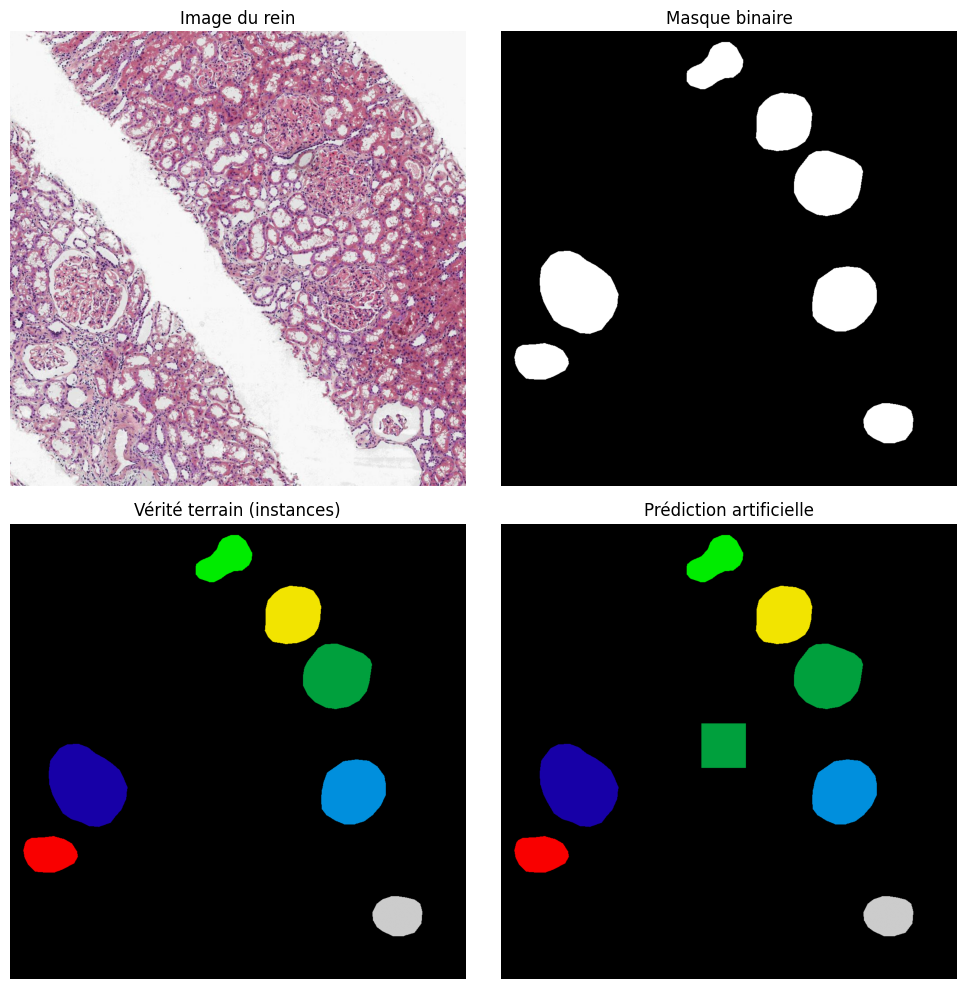

In [ ]:
# --- Lecture de l'image ---
X = cv2.imread(str(DATA_DIR / "train03/4389_HE.png_2588_1392.png"))
X = cv2.cvtColor(X, cv2.COLOR_BGR2RGB)          # BGR -> RGB pour matplotlib
h, w, n_channels = X.shape
print(f"Image : hauteur={h}, largeur={w}, canaux={n_channels}")

# --- Lecture du masque d'instances ---
y_true = cv2.imread(str(DATA_DIR / "train03/4389_HE.png_2588_1392_mask.tif"), cv2.IMREAD_UNCHANGED)
ids = np.unique(y_true)                          # liste des valeurs présentes : 0 (fond) + un numéro par glomérule
print(f"Masque : forme={y_true.shape}, valeurs={ids.tolist()}, nb glomérules={len(ids) - 1}")

# --- Fausse prédiction pour illustrer le Dice ---
# On recopie la vérité terrain et on "abîme" un carré de 100x100 pixels au centre.
y_pred = y_true.copy()
y_pred[450:550, 450:550] = 3

# --- Affichage ---
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(X)
axes[0, 0].set_title("Image du rein")
axes[0, 1].imshow(y_true > 0, cmap="gray")       # > 0 : binarisation (tout glomérule = blanc)
axes[0, 1].set_title("Masque binaire")
axes[1, 0].imshow(y_true, cmap="nipy_spectral", vmin=0, vmax=max(1, y_true.max()))
axes[1, 0].set_title("Vérité terrain (instances)")
axes[1, 1].imshow(y_pred, cmap="nipy_spectral", vmin=0, vmax=max(1, y_true.max()))
axes[1, 1].set_title("Prédiction artificielle")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Métrique Dice et encodage RLE

### Le Dice
On écrit une fonction `dice(pred, true)` qui :
1. convertit les deux masques en booléens ;
2. compte les pixels communs (intersection) ;
3. applique la formule `2·|A∩B| / (|A|+|B|)`.

Cas particulier : si les deux masques sont **vides** (aucun glomérule, ni prédit ni réel), la prédiction est parfaite → on renvoie 1.

### Le RLE (*run-length encoding*)
Le fichier de soumission ne contient pas d'images : chaque masque est **compressé en texte**. On lit les pixels ligne par ligne et on note uniquement les « plages » de 1 sous la forme `début longueur début longueur ...` (positions numérotées à partir de 1).

Exemple : la ligne de pixels `0 0 1 1 1 0 1` donne `3 3 7 1` (une plage de 3 pixels qui commence en position 3, une plage de 1 pixel en position 7).

On reprend le code du notebook Kaggle cité dans le sujet, et on vérifie qu'un aller-retour encodage → décodage redonne exactement le masque.

### Ce qu'on attend des trois tests ci-dessous
1. masque comparé à lui-même → **1** ;
2. masque légèrement abîmé → proche de 1 ;
3. masque aléatoire → très faible.

In [ ]:
def convert_to_binary(y):
    # Masque d'instances (0, 1, 2, ...) -> masque binaire (True = glomérule)
    return y > 0


def dice(pred, true):
    # Dice entre deux masques binaires (numpy ou torch, n'importe quelle forme identique)
    pred = np.asarray(pred, dtype=bool)
    true = np.asarray(true, dtype=bool)
    if pred.shape != true.shape:
        raise ValueError(f"Formes différentes : {pred.shape} vs {true.shape}")
    denom = pred.sum() + true.sum()                  # |A| + |B|
    if denom == 0:                                   # deux masques vides = prédiction parfaite
        return 1.0
    intersection = np.logical_and(pred, true).sum()  # |A ∩ B|
    return float(2.0 * intersection / denom)


def rle_encode(mask):
    # Masque binaire (H, W) -> chaîne RLE "début longueur début longueur ..." (positions 1-indexées)
    pixels = np.asarray(mask, dtype=np.uint8).flatten()      # lecture ligne par ligne
    pixels = np.concatenate([[0], pixels, [0]])              # zéros aux bords pour détecter début et fin
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1        # positions où la valeur change
    runs[1::2] -= runs[::2]                                  # (début, fin) -> (début, longueur)
    return " ".join(str(x) for x in runs)


def rle_decode(rle, shape):
    # Chaîne RLE -> masque binaire (H, W) : opération inverse de rle_encode
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if rle:
        s = np.asarray(rle.split(), dtype=int)
        for start, length in zip(s[0::2] - 1, s[1::2]):      # -1 : on repasse en indices 0-indexés
            mask[start:start + length] = 1
    return mask.reshape(shape).astype(bool)


# --- Tests de la métrique ---
yb_true = convert_to_binary(y_true)
yb_pred = convert_to_binary(y_pred)
print(f"1) Dice (même masque)          : {dice(yb_true, yb_true):.4f}")
print(f"2) Dice (prédiction modifiée)  : {dice(yb_pred, yb_true):.4f}")
print(f"3) Dice (masque aléatoire)     : {dice(np.random.rand(*yb_true.shape) > 0.5, yb_true):.4f}")

# --- Test du RLE : encoder puis décoder doit redonner exactement le même masque ---
assert np.array_equal(rle_decode(rle_encode(yb_true), yb_true.shape), yb_true)
print("RLE : encodage/décodage vérifié. Début de la chaîne :", rle_encode(yb_true)[:60], "...")

1) Dice (même masque)          : 1.0000
2) Dice (prédiction modifiée)  : 0.9506
3) Dice (masque aléatoire)     : 0.1541
RLE : encodage/décodage vérifié. Début de la chaîne : 28144 19 29166 22 30187 26 31209 30 32231 33 33252 37 34274  ...


## 3. Données : train03 pour l'entraînement, train_AKI pour la validation

Chaque échantillon est une paire `<nom>.png` (image RGB) / `<nom>_mask.tif` (masque d'**instances** : `0` = fond, chaque glomérule porte son numéro). On binarise le masque (`> 0`) car le Dice compare des masques binaires.

| Dossier | Rôle | Contenu |
|---|---|---|
| `train03` | **entraînement** | 42 images d'une seule lame de rein de rongeur (`4389`), en 3 colorations : HE (rose), PAS (violet), PASM (argent, noir). Les 13 masques `4389_MAS` n'ont pas d'image : ils sont ignorés |
| `train_AKI` | **validation** | 11 images de rein **humain** pathologique (*acute kidney injury*), coloration PAS, autre scanner. Glomérules ≈ 1.35× plus gros, texture différente |

Ce découpage est volontairement **difficile** : le modèle n'a jamais vu de rein humain. Le Dice sur `train_AKI` est donc une bonne estimation de ce qui se passera sur les images inconnues des organisateurs.

> Pas de fuite de données : aucune image de validation n'est utilisée pour l'entraînement. La validation sert uniquement à choisir le meilleur epoch, puis le seuil et le mode de prédiction (section 7). Le score obtenu est donc légèrement optimiste.

La lecture des images passe par `read_rgb`, qui accepte aussi les images en niveaux de gris, avec canal alpha ou en 16 bits. Le modèle ne plantera pas sur un format inattendu chez les organisateurs. Une image AKI fait d'ailleurs 1024 × 1023 : **tout le pipeline accepte des tailles quelconques**.

In [ ]:
def list_pairs(directory):
    # Pour chaque masque "<nom>_mask.tif", cherche l'image "<nom>.png" correspondante.
    # Renvoie la liste des paires trouvées + la liste des masques sans image.
    pairs, orphans = [], []
    for mask_path in sorted(Path(directory).glob("*_mask.tif")):
        img_path = mask_path.with_name(mask_path.name.replace("_mask.tif", ".png"))
        if img_path.exists():
            pairs.append((img_path, mask_path))
        else:
            orphans.append(mask_path.name)
    return pairs, orphans


def read_rgb(path):
    # Lecture robuste d'une image en RGB uint8 (gère niveaux de gris, canal alpha, images 16 bits)
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(path)
    if image.dtype != np.uint8:                                   # ex. 16 bits -> 8 bits
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    if image.ndim == 2:                                           # niveaux de gris -> 3 canaux
        return cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    if image.shape[2] == 4:                                       # BGRA -> RGB (on ignore la transparence)
        return cv2.cvtColor(image, cv2.COLOR_BGRA2RGB)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def read_mask(path):
    # Masque d'instances -> masque binaire (True = glomérule)
    return cv2.imread(str(path), cv2.IMREAD_UNCHANGED) > 0


train_pairs, orphans = list_pairs(TRAIN_DIR)
val_pairs, _ = list_pairs(VAL_DIR)
print(f"Entraînement ({TRAIN_DIR.name}) : {len(train_pairs)} paires ({len(orphans)} masques sans image ignorés)")
print(f"Validation   ({VAL_DIR.name}) : {len(val_pairs)} paires")
assert not {p[0].name for p in train_pairs} & {p[0].name for p in val_pairs}   # aucune image commune


def describe(pairs, name):
    # Quelques statistiques sur un ensemble : taille des images, proportion de glomérule, diamètre des glomérules
    fg, n_inst, sizes, shapes = [], [], [], set()
    for _, mp in pairs:
        m = cv2.imread(str(mp), cv2.IMREAD_UNCHANGED)
        shapes.add(m.shape)
        fg.append((m > 0).mean())
        ids = [i for i in np.unique(m) if i > 0]
        n_inst.append(len(ids))
        sizes += [np.sqrt((m == i).sum()) for i in ids]          # "diamètre" ≈ racine de l'aire
    print(f"{name:<10}: tailles {sorted(shapes)}, {np.mean(fg) * 100:.1f}% de pixels glomérule, "
          f"{np.mean(n_inst):.1f} glomérules/image, diamètre médian ≈ {np.median(sizes):.0f} px")


describe(train_pairs, TRAIN_DIR.name)
describe(val_pairs, VAL_DIR.name)

Entraînement (train03) : 42 paires (13 masques sans image ignorés)
Validation   (train_AKI) : 11 paires


train03   : tailles [(1024, 1024)], 5.4% de pixels glomérule, 5.1 glomérules/image, diamètre médian ≈ 106 px


train_AKI : tailles [(1024, 1023), (1024, 1024)], 5.4% de pixels glomérule, 2.8 glomérules/image, diamètre médian ≈ 142 px


## 4. Augmentation de données

### Pourquoi ?
42 images, toutes issues **de la même lame**, c'est beaucoup trop peu pour entraîner un réseau de zéro. Sans augmentation, le réseau apprend ces 42 images par cœur (couleurs exactes, taille exacte des glomérules) et échoue sur toute autre lame.

L'augmentation fabrique de **nouvelles images d'entraînement réalistes** à partir des 42 originales. Chaque transformation simule une variation qu'on rencontrera sur les images de test.

### Augmentation « à la volée » plutôt que sur disque
Plutôt que de générer une fois pour toutes quelques milliers d'images augmentées, on tire **une nouvelle transformation aléatoire à chaque fois** qu'une image est demandée. Avec 42 images × 8 versions par epoch × 60 epochs, le réseau voit **≈ 20 000 images d'entraînement toutes différentes**, sans rien stocker. Une version figée sur disque serait vue plusieurs fois à l'identique et favoriserait le sur-apprentissage.

### Les transformations

**Géométriques** (même transformation pour l'image et le masque, qui restent alignés) :

| Transformation | Ce qu'elle simule |
|---|---|
| crop centré sur un glomérule (60 %) ou n'importe où (40 %) | rééquilibre glomérule / fond (5 % de pixels glomérule seulement) |
| **zoom** log-uniforme entre ×0.55 et ×1.8 | autres espèces (rat, souris, humain), autres grossissements du scanner |
| rotation d'angle quelconque + miroir | un glomérule n'a pas d'orientation privilégiée |
| déformation élastique (Simard et al., 2003) | tissus étirés ou écrasés à la coupe |

**Couleur** (image seule) :

| Transformation | Ce qu'elle simule |
|---|---|
| **perturbation des colorants H&E** (déconvolution de Ruifrok & Johnston, perturbation de Tellez et al.) | une coloration plus ou moins intense selon le laboratoire |
| teinte / saturation / luminosité (HSV) | d'autres colorations (HE, PAS, PASM, trichrome...) |
| contraste, gamma | réglages différents du scanner |
| niveaux de gris (10 %), permutation des canaux (5 %) | obliger le réseau à reconnaître la **forme** du glomérule, pas seulement sa couleur |

**Qualité d'acquisition** (image seule) : flou gaussien (mise au point), bruit (capteur), compression JPEG.

Les augmentations ne sont utilisées **qu'à l'entraînement**. La validation se fait sur les vraies images entières, à leur taille d'origine.

In [ ]:
def to_working_scale(image, mask=None, scale=SCALE):
    # Réduit l'image (et le masque) à la résolution de travail du réseau
    h, w = image.shape[:2]
    size = (max(1, round(w * scale)), max(1, round(h * scale)))   # cv2 attend (largeur, hauteur)
    image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
    if mask is None:
        return image
    # Masque réduit en flottant puis re-seuillé : contours plus fidèles qu'avec INTER_NEAREST
    mask = cv2.resize(mask.astype(np.float32), size, interpolation=cv2.INTER_AREA) > 0.5
    return image, mask


def normalize_image(image):
    # uint8 (H, W, 3) -> float32 (3, H, W), valeurs centrées autour de 0
    x = (image.astype(np.float32) / 255.0 - 0.5) / 0.25
    return np.ascontiguousarray(x.transpose(2, 0, 1))


# ---------------------------------------------------------------------
# 1) Augmentations géométriques (appliquées à l'image ET au masque)
# ---------------------------------------------------------------------
def random_affine_crop(image, mask, fg_coords, crop=CROP_SIZE):
    # Un seul warpAffine fait à la fois : choix du centre, zoom, rotation d'angle quelconque et découpe
    h, w = mask.shape
    if len(fg_coords) and np.random.rand() < POS_CROP_PROB:
        cy, cx = fg_coords[np.random.randint(len(fg_coords))]       # centre sur un pixel de glomérule
        cy, cx = cy + np.random.uniform(-crop / 3, crop / 3), cx + np.random.uniform(-crop / 3, crop / 3)
    else:
        cy, cx = np.random.uniform(0, h), np.random.uniform(0, w)    # centre quelconque
    zoom = np.exp(np.random.uniform(np.log(ZOOM_RANGE[0]), np.log(ZOOM_RANGE[1])))   # zoom log-uniforme
    angle = np.random.uniform(0, 360)
    M = cv2.getRotationMatrix2D((float(cx), float(cy)), angle, zoom)
    M[:, 2] += (crop / 2 - cx, crop / 2 - cy)                        # le centre choisi va au milieu du crop
    # BORDER_REFLECT_101 : hors de l'image, on prolonge par symétrie (image et masque de la même façon)
    image = cv2.warpAffine(image, M, (crop, crop), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.warpAffine(mask.astype(np.uint8), M, (crop, crop), flags=cv2.INTER_NEAREST,
                          borderMode=cv2.BORDER_REFLECT_101)
    if np.random.rand() < 0.5:                                       # symétrie miroir
        image, mask = image[:, ::-1], mask[:, ::-1]
    return np.ascontiguousarray(image), np.ascontiguousarray(mask)


def elastic_deform(image, mask, alpha=120.0, sigma=8.0):
    # Déformation élastique douce (Simard et al., 2003) : champ de déplacement aléatoire lissé
    # (≈ 3 px en moyenne), simule des tissus étirés / déformés à la coupe
    h, w = mask.shape
    dx = cv2.GaussianBlur(np.random.uniform(-1, 1, (h, w)).astype(np.float32), (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur(np.random.uniform(-1, 1, (h, w)).astype(np.float32), (0, 0), sigma) * alpha
    gx, gy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    map_x, map_y = gx + dx, gy + dy
    image = cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.remap(mask, map_x, map_y, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return image, mask


# ---------------------------------------------------------------------
# 2) Augmentations de couleur et de qualité (image seulement)
# ---------------------------------------------------------------------
# Déconvolution de couleur de Ruifrok & Johnston (2001) : passage RGB <-> concentrations de colorants
# (Hématoxyline, Éosine, DAB). On perturbe chaque colorant séparément (Tellez et al., 2018).
RGB_FROM_HED = np.array([[0.65, 0.70, 0.29],
                         [0.07, 0.99, 0.11],
                         [0.27, 0.57, 0.78]], dtype=np.float32)
HED_FROM_RGB = np.linalg.inv(RGB_FROM_HED).astype(np.float32)


def hed_jitter(image, sigma=0.35, bias=0.03):
    od = -np.log((image.astype(np.float32) + 1.0) / 256.0)          # densité optique (loi de Beer-Lambert)
    hed = od.reshape(-1, 3) @ HED_FROM_RGB                           # quantité de chaque colorant
    hed = hed * np.random.uniform(1 - sigma, 1 + sigma, 3) + np.random.uniform(-bias, bias, 3)
    od = (hed @ RGB_FROM_HED).reshape(image.shape)
    return np.clip(np.exp(-od) * 256.0 - 1.0, 0, 255).astype(np.uint8)


def hsv_jitter(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + np.random.uniform(-15, 15)) % 180   # teinte (0-179 dans OpenCV)
    hsv[..., 1] *= np.random.uniform(0.6, 1.4)                       # saturation
    hsv[..., 2] *= np.random.uniform(0.8, 1.2)                       # luminosité
    return cv2.cvtColor(np.clip(hsv, 0, 255).astype(np.uint8), cv2.COLOR_HSV2RGB)


def contrast_gamma(image):
    x = image.astype(np.float32) / 255.0
    x = (x - x.mean()) * np.random.uniform(0.7, 1.3) + x.mean() + np.random.uniform(-0.08, 0.08)
    x = np.clip(x, 0, 1) ** np.random.uniform(0.7, 1.5)              # correction gamma
    return (x * 255).astype(np.uint8)


def color_augment(image):
    if np.random.rand() < 0.8:
        image = hed_jitter(image)
    if np.random.rand() < 0.7:
        image = hsv_jitter(image)
    if np.random.rand() < 0.7:
        image = contrast_gamma(image)
    if np.random.rand() < 0.1:                                       # niveaux de gris : forcer à regarder la forme
        image = cv2.cvtColor(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), cv2.COLOR_GRAY2RGB)
    if np.random.rand() < 0.05:                                      # permutation des canaux : couleurs « exotiques »
        image = np.ascontiguousarray(image[..., np.random.permutation(3)])
    return image


def quality_augment(image):
    # Défauts d'acquisition : mise au point (flou), bruit du capteur, compression JPEG
    if np.random.rand() < 0.25:
        image = cv2.GaussianBlur(image, (0, 0), np.random.uniform(0.3, 1.5))
    if np.random.rand() < 0.25:
        noise = np.random.normal(0, np.random.uniform(2, 10), image.shape)
        image = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    if np.random.rand() < 0.2:
        ok, buf = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, np.random.randint(40, 90)])
        image = cv2.imdecode(buf, cv2.IMREAD_UNCHANGED)
    return image


def augment(image, mask, fg_coords):
    # Chaîne complète : géométrie (image + masque) puis couleur et qualité (image seule)
    image, mask = random_affine_crop(image, mask, fg_coords)
    if np.random.rand() < 0.3:
        image, mask = elastic_deform(image, mask)
    image = quality_augment(color_augment(image))
    return image, mask


# ---------------------------------------------------------------------
# 3) Datasets PyTorch
# ---------------------------------------------------------------------
class AugmentedGlomeruliDataset(Dataset):
    # Chaque appel à __getitem__ fabrique une NOUVELLE image augmentée : le jeu de données est
    # virtuellement infini. len = nombre d'images x SAMPLES_PER_IMAGE (= taille d'une epoch).
    def __init__(self, pairs, samples_per_image=SAMPLES_PER_IMAGE):
        self.pairs = pairs
        self.samples_per_image = samples_per_image
        self.images, self.masks, self.fg_coords = [], [], []
        for img_path, mask_path in tqdm(pairs, desc="Chargement train", leave=False):
            image, mask = to_working_scale(read_rgb(img_path), read_mask(mask_path))
            self.images.append(image)
            self.masks.append(mask)
            self.fg_coords.append(np.argwhere(mask))                 # positions des pixels glomérule

    def __len__(self):
        return len(self.pairs) * self.samples_per_image

    def __getitem__(self, idx):
        i = idx % len(self.pairs)
        image, mask = augment(self.images[i], self.masks[i], self.fg_coords[i])
        x = torch.from_numpy(normalize_image(image))                  # (3, H, W)
        y = torch.from_numpy(mask.astype(np.float32)).unsqueeze(0)    # (1, H, W)
        return x, y


class FullImageDataset:
    # Validation / test : images entières, à leur taille d'origine, sans augmentation
    def __init__(self, pairs):
        self.pairs = pairs
        self.images = [read_rgb(p) for p, _ in tqdm(pairs, desc="Chargement validation", leave=False)]
        self.masks = [read_mask(m) for _, m in pairs]

    def __len__(self):
        return len(self.pairs)


train_dataset = AugmentedGlomeruliDataset(train_pairs)
val_dataset = FullImageDataset(val_pairs)

# Sous Windows, garder num_workers=0 (les workers multiples posent problème dans un notebook)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
print(f"Train : {len(train_pairs)} images -> {len(train_dataset)} images augmentées par epoch, "
      f"{len(train_dataset) * NUM_EPOCHS} au total sur {NUM_EPOCHS} epochs (toutes différentes)")
print(f"Validation : {len(val_dataset)} images à pleine résolution")

Chargement train:   0%|          | 0/42 [00:00<?, ?it/s]

Chargement validation:   0%|          | 0/11 [00:00<?, ?it/s]

Train : 42 images -> 336 images augmentées par epoch, 20160 au total sur 60 epochs (toutes différentes)
Validation : 11 images à pleine résolution


### Contrôle visuel des augmentations

Pour une image de chaque coloration, on affiche l'originale puis 6 tirages augmentés. Le contour vert est le masque **transformé** : il doit rester parfaitement collé aux glomérules. Si ce n'est pas le cas, l'image et le masque ne subissent pas la même transformation, et le réseau apprendrait n'importe quoi.

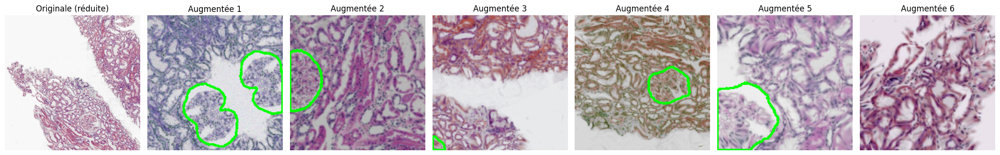

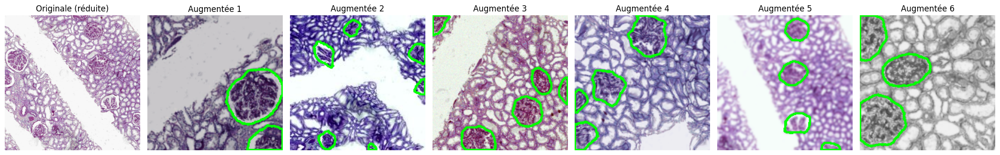

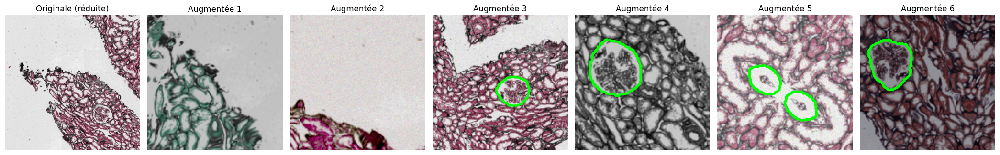

In [ ]:
def show_augmentations(dataset, image_index, n=6):
    # Affiche l'image d'origine puis n versions augmentées, avec le contour du masque en vert
    fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3.2))
    axes[0].imshow(dataset.images[image_index])
    axes[0].set_title("Originale (réduite)")
    for j in range(1, n + 1):
        x, y = dataset[image_index]                                  # nouveau tirage aléatoire à chaque appel
        img = np.clip(x.numpy().transpose(1, 2, 0) * 0.25 + 0.5, 0, 1)   # on annule la normalisation
        img = (img * 255).astype(np.uint8).copy()
        contours, _ = cv2.findContours(y[0].numpy().astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(img, contours, -1, (0, 255, 0), 2)
        axes[j].imshow(img)
        axes[j].set_title(f"Augmentée {j}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Une image de chaque coloration du jeu d'entraînement (HE, PAS, PASM)
for stain in ["_HE.", "_PAS.", "_PASM."]:
    idx = next(i for i, (p, _) in enumerate(train_pairs) if stain in p.name)
    show_augmentations(train_dataset, idx)

## 5. Le modèle : U-Net résiduel construit de zéro

### Architecture
Le **U-Net** (Ronneberger et al., 2015) est l'architecture de référence en segmentation biomédicale. Notre version, pour une entrée de 192 × 192 :

```
entrée 3×192×192                                                     sortie 1×192×192
  │ stem   bloc résiduel (16)          192 ─────────────────────► concat → bloc (16) → conv 1×1
  │ enc1   bloc résiduel /2 (32)        96 ──────────────► concat → bloc (32) ▲
  │ enc2   bloc résiduel /2 (64)        48 ────────► concat → bloc (64) ▲
  │ enc3   bloc résiduel /2 (128)       24 ──► concat → bloc (128) ▲
  └ enc4   bloc résiduel /2 (256)       12 ─┘ (dropout) ×2
```

- **Encodeur** (descente) : la taille est divisée par 2 à chaque niveau, le nombre de filtres doublé. Les niveaux profonds « voient » une grande zone : ils reconnaissent **ce qu'est** l'objet.
- **Décodeur** (remontée) : agrandissement ×2 et concaténation avec la carte de même taille de l'encodeur (*skip connection*). Il retrouve **où** est l'objet, avec des contours précis.
- **Blocs résiduels** (He et al., 2016) : chaque bloc calcule `ReLU(F(x) + x)`. Le gradient circule mieux, ce qui facilite l'entraînement **de zéro**.
- **BatchNorm** après chaque convolution : entraînement plus stable.
- **Dropout** au fond du U : régularisation, utile avec si peu de données.
- **Initialisation** : poids de He (adaptés à ReLU) et biais de sortie réglé pour prédire ≈ 5 % de glomérule au départ (la proportion réelle). Les premières itérations ne sont pas gaspillées à apprendre que le fond domine.

Le réseau est **entièrement convolutif** : il accepte n'importe quelle taille d'image (y compris non carrée, voir le test ci-dessous).

### Pourquoi un réseau compact (≈ 2 M de paramètres) ?
Avec 42 images, un grand réseau aurait tendance à mémoriser. Un réseau compact généralise mieux et s'entraîne en ≈ 3 h sur CPU. Nous avons mesuré qu'un U-Net à 32 filtres de base est ≈ 6× plus lent sur cette machine.

In [ ]:
class ResidualBlock(nn.Module):
    # 2 x (convolution 3x3 -> BatchNorm) + connexion résiduelle (He et al., 2016) : y = ReLU(F(x) + x)
    # stride=2 : le bloc divise aussi la taille de l'image par 2 (descente du U-Net)
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        # Si la forme change (canaux ou taille), le raccourci passe par une convolution 1x1
        self.shortcut = nn.Identity() if (in_ch == out_ch and stride == 1) else nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)), inplace=True)
        y = self.bn2(self.conv2(y))
        return F.relu(y + self.shortcut(x), inplace=True)


class UNet(nn.Module):
    # U-Net résiduel construit de zéro, poids initialisés aléatoirement (aucun pré-entraînement)
    def __init__(self, base_channels=BASE_CHANNELS, depth=DEPTH, dropout=DROPOUT):
        super().__init__()
        ch = [base_channels * 2 ** i for i in range(depth)]          # ex. 16, 32, 64, 128, 256
        self.stem = ResidualBlock(3, ch[0])                          # niveau 0 : pleine résolution
        self.encoder = nn.ModuleList(                                # niveaux 1..depth-1 : taille / 2 à chaque fois
            ResidualBlock(ch[i - 1], ch[i], stride=2) for i in range(1, depth))
        self.dropout = nn.Dropout2d(dropout)                         # régularisation au fond du U
        self.decoder = nn.ModuleList(                                # remontée : [agrandi, skip] -> bloc
            ResidualBlock(ch[i] + ch[i - 1], ch[i - 1]) for i in range(depth - 1, 0, -1))
        self.head = nn.Conv2d(ch[0], 1, kernel_size=1)               # 1 score (logit) par pixel
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")   # init. de He
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        # Biais de sortie = log(p / (1 - p)) avec p ≈ 5 % de pixels glomérule : le réseau part d'une
        # prédiction « presque tout fond », ce qui stabilise le début de l'entraînement
        nn.init.constant_(self.head.bias, float(np.log(0.05 / 0.95)))

    def forward(self, x):
        skips = [self.stem(x)]
        for block in self.encoder:                                   # descente
            skips.append(block(skips[-1]))
        y = self.dropout(skips.pop())
        for block in self.decoder:                                   # remontée
            skip = skips.pop()
            y = F.interpolate(y, size=skip.shape[2:], mode="bilinear", align_corners=False)
            y = block(torch.cat([y, skip], dim=1))
        return self.head(y)                                          # logits (pas encore de sigmoid)


model = UNet().to(device)
print(f"Nombre de paramètres : {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M (tous entraînés de zéro)")

with torch.no_grad():
    model.eval()
    for shape in [(1, 3, 192, 192), (1, 3, 384, 384), (1, 3, 384, 383)]:   # taille quelconque acceptée
        print(f"Entrée {shape} -> sortie {tuple(model(torch.zeros(shape, device=device)).shape)}")

Nombre de paramètres : 2.07 M (tous entraînés de zéro)


Entrée (1, 3, 192, 192) -> sortie (1, 1, 192, 192)


Entrée (1, 3, 384, 384) -> sortie (1, 1, 384, 384)


Entrée (1, 3, 384, 383) -> sortie (1, 1, 384, 383)


## 6. Entraînement

### Fonction de perte : BCE + Dice
- **BCE** (*binary cross-entropy*) : pénalise chaque pixel mal classé. Elle donne des gradients stables, mais seule elle pousse à tout prédire en fond (95 % des pixels).
- **Dice loss** = `1 − Dice` calculé sur les probabilités. Elle optimise directement la métrique du challenge et n'est pas sensible au déséquilibre. On la calcule sur **tout le batch** : un crop sans glomérule ne produit pas de perte absurde.

### Optimisation
- **AdamW** avec *weight decay* (régularisation des poids).
- **OneCycle** : le taux d'apprentissage monte pendant les 10 premiers % (*warm-up*), puis redescend en cosinus vers 0.
- **EMA** (*exponential moving average*) des poids : `w_ema ← 0.99·w_ema + 0.01·w` après chaque batch. Le modèle moyenné est moins sensible au bruit des derniers batchs. C'est lui qu'on valide et qu'on sauvegarde.

### Fonctions de prédiction (réutilisées partout ensuite)
`predict_proba` : image d'origine → réduction (×0.375) → réseau → probabilités → **retour à la taille d'origine**. Le Dice est donc calculé à la résolution du challenge. Deux options :
- `tta=True` : moyenne des prédictions sur les **8 symétries** de l'image (4 rotations × miroir) ;
- `zooms=(0.8, 1.0, 1.25)` : moyenne sur **plusieurs échelles**, utile si les glomérules des images de test sont plus gros ou plus petits.

### La boucle
À chaque epoch : entraînement sur 336 nouvelles images augmentées → Dice sur `train_AKI` (pleine résolution, seuil 0.5) → sauvegarde si c'est le meilleur.

> On peut interrompre l'entraînement à tout moment : le meilleur modèle est déjà sauvegardé dans `unet_scratch_weights.pth`. Avec `TRAIN_MODEL = False`, cette cellule ne fait que définir les fonctions.

In [ ]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

# ---------------------------------------------------------------------
# Fonction de perte : BCE + Dice « doux »
# ---------------------------------------------------------------------
def dice_loss(logits, target, smooth=1.0):
    # 1 - Dice calculé sur tout le batch (un crop sans glomérule ne donne pas une perte absurde)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum()
    return 1.0 - (2.0 * inter + smooth) / (prob.sum() + target.sum() + smooth)


bce = nn.BCEWithLogitsLoss()


def criterion(logits, target):
    return bce(logits, target) + dice_loss(logits, target)


# ---------------------------------------------------------------------
# Prédiction sur une image entière (n'importe quelle taille)
# ---------------------------------------------------------------------
# Les 8 symétries du carré (groupe diédral D4) : 4 rotations de 90°, avec ou sans miroir
D4 = [(k, flip) for flip in (False, True) for k in range(4)]


@torch.no_grad()
def predict_proba(model, image_rgb, tta=False, zooms=(1.0,), scale=SCALE):
    # Image RGB uint8 (H, W, 3) -> carte de probabilités (H, W) à la taille d'origine
    # tta=True : moyenne sur les 8 symétries ; zooms : moyenne sur plusieurs échelles d'entrée
    model.eval()
    h, w = image_rgb.shape[:2]
    total = np.zeros((h, w), dtype=np.float32)
    for z in zooms:
        x = torch.from_numpy(normalize_image(to_working_scale(image_rgb, scale=scale * z))).unsqueeze(0).to(device)
        transforms = D4 if tta else D4[:1]
        prob = 0
        for k, flip in transforms:
            xi = torch.rot90(x, k, dims=(2, 3))
            xi = torch.flip(xi, dims=(3,)) if flip else xi
            p = torch.sigmoid(model(xi))
            p = torch.flip(p, dims=(3,)) if flip else p                  # on annule le miroir...
            prob = prob + torch.rot90(p, -k, dims=(2, 3))                # ... puis la rotation
        prob = (prob / len(transforms))[0, 0].cpu().numpy()
        total += cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)   # retour à la taille d'origine
    return total / len(zooms)


def predict_dataset(model, dataset, **kwargs):
    return [predict_proba(model, image, **kwargs) for image in dataset.images]


def mean_dice(probs, masks, threshold=0.5, postprocess=None):
    # Dice moyen sur un ensemble d'images, pour un seuil (et un post-traitement) donnés
    scores = []
    for p, m in zip(probs, masks):
        pred = p > threshold
        if postprocess is not None:
            pred = postprocess(pred)
        scores.append(dice(pred, m))
    return float(np.mean(scores))


# ---------------------------------------------------------------------
# Optimiseur, scheduler, moyenne glissante des poids (EMA)
# ---------------------------------------------------------------------
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, total_steps=NUM_EPOCHS * len(train_loader), pct_start=0.1)
# ema_model contient la moyenne glissante des poids : w_ema <- 0.99 w_ema + 0.01 w
ema_model = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)


def save_checkpoint(net, path, **extra):
    # On sauvegarde les poids, l'architecture / la résolution (le fichier suffit pour prédire)
    # et l'historique d'entraînement (pour retracer les courbes sans réentraîner)
    config = {"base_channels": BASE_CHANNELS, "depth": DEPTH, "dropout": DROPOUT, "scale": SCALE}
    config.update(extra)
    torch.save({"state_dict": net.state_dict(), "config": config, "history": history}, path)


# ---------------------------------------------------------------------
# Boucle d'entraînement
# ---------------------------------------------------------------------
history = {"train_loss": [], "val_dice": []}
best_val_dice = -1.0
t0 = time.time()

for epoch in range(NUM_EPOCHS if TRAIN_MODEL else 0):
    # --- 1) Entraînement sur des images augmentées toutes nouvelles ---
    model.train()
    running_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), masks)
        loss.backward()
        optimizer.step()
        scheduler.step()
        ema_model.update_parameters(model)                   # mise à jour de la moyenne des poids
        running_loss += loss.item()

    # --- 2) Validation sur train_AKI, à pleine résolution, avec le modèle moyenné ---
    train_loss = running_loss / len(train_loader)
    val_dice = mean_dice(predict_dataset(ema_model.module, val_dataset), val_dataset.masks)
    history["train_loss"].append(train_loss)
    history["val_dice"].append(val_dice)

    # --- 3) Sauvegarde du meilleur modèle ---
    flag = ""
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        save_checkpoint(ema_model.module, WEIGHTS_PATH)
        flag = "  <- meilleur"
    print(f"Epoch {epoch + 1:3d}/{NUM_EPOCHS} - train_loss={train_loss:.4f} - val_dice={val_dice:.4f} "
          f"- lr={optimizer.param_groups[0]['lr']:.1e} - {time.time() - t0:.0f}s{flag}", flush=True)

if TRAIN_MODEL:
    print(f"\nMeilleur Dice validation (seuil 0.5, sans TTA) = {best_val_dice:.4f} -> {WEIGHTS_PATH}")

### Courbes d'apprentissage

- **Train loss** : doit descendre. Elle reste assez haute car les images augmentées sont volontairement difficiles.
- **Dice validation** (`train_AKI`, domaine jamais vu) : doit monter puis se stabiliser. Les oscillations viennent du petit nombre d'images de validation (11) ; l'EMA les atténue.
- Si la loss baisse alors que le Dice de validation baisse : **sur-apprentissage** sur la lame de rongeur.

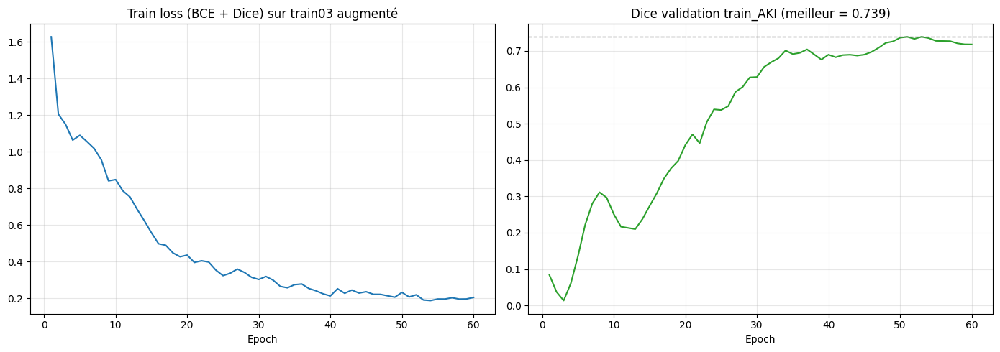

In [ ]:
if not history["train_loss"]:
    # Entraînement sauté (TRAIN_MODEL = False) : on relit l'historique enregistré avec les poids
    history = torch.load(WEIGHTS_PATH, map_location="cpu").get("history", history)
    best_val_dice = max(history["val_dice"], default=float("nan"))
if not history["train_loss"]:
    print("Pas de courbes : aucun historique disponible.")
else:
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs, history["train_loss"], color="tab:blue")
    axes[0].set_title("Train loss (BCE + Dice) sur train03 augmenté")
    axes[1].plot(epochs, history["val_dice"], color="tab:green")
    axes[1].axhline(best_val_dice, color="gray", linestyle="--", linewidth=1)
    axes[1].set_title(f"Dice validation train_AKI (meilleur = {best_val_dice:.3f})")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 7. Évaluation : TTA, multi-échelle, seuil, post-traitement

Sans réentraîner, plusieurs réglages améliorent le Dice :

1. **Le mode de prédiction** : simple, TTA 8 symétries, ou TTA + 3 échelles. Les erreurs aléatoires du réseau se compensent dans la moyenne, et le multi-échelle protège contre des glomérules de taille inhabituelle. On teste deux jeux d'échelles : (0.8, 1.0, 1.25), centré, et (0.6, 0.8, 1.0), qui réduit l'image. Ce second jeu vient d'un diagnostic fait pendant la mise au point : les glomérules humains, plus gros que ceux du rongeur, sont mieux reconnus quand on réduit l'image (Dice 0.31 → 0.35 au zoom 0.6, sur un modèle intermédiaire).
2. **Le seuil** : « glomérule » si probabilité > seuil. On teste de 0.30 à 0.75.
3. **Le post-traitement** : suppression des taches de moins de `MIN_AREA` pixels (faux positifs isolés) et remplissage des trous à l'intérieur de chaque glomérule.

On retient la combinaison qui maximise le Dice moyen sur `train_AKI`. Ce réglage est **enregistré dans le fichier de poids**, à côté de l'architecture et de la résolution. Le fichier `unet_scratch_weights.pth` suffit donc pour reproduire exactement nos prédictions sur d'autres images (section 9).

> Le réglage est choisi sur la validation : le score affiché est un peu optimiste. Le seuil et le mode restent des choix grossiers (quelques valeurs testées), le risque de sur-ajustement est donc faible.

In [ ]:
MIN_AREA = 1000   # aire minimale d'un glomérule, en pixels de l'image d'origine (un glomérule ≈ 10 000 px)


def postprocess(mask, min_area=MIN_AREA):
    # Supprime les petites taches et remplit les trous de chaque glomérule
    mask = mask.astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)   # contours extérieurs
    out = np.zeros_like(mask)
    for c in contours:
        if cv2.contourArea(c) >= min_area:
            cv2.drawContours(out, [c], -1, 1, thickness=cv2.FILLED)   # contour rempli = trous bouchés
    return out.astype(bool)


# Rechargement du meilleur modèle (moyenne EMA des poids) sauvegardé pendant l'entraînement
model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device)["state_dict"])

# Quatre façons de prédire, de la plus rapide à la plus robuste
MODES = {
    "simple": dict(tta=False, zooms=(1.0,)),
    "TTA 8 sym.": dict(tta=True, zooms=(1.0,)),
    "TTA éch. 0.8-1.25": dict(tta=True, zooms=(0.8, 1.0, 1.25)),
    "TTA éch. 0.6-1.0": dict(tta=True, zooms=(0.6, 0.8, 1.0)),
}
val_probs = {name: predict_dataset(model, val_dataset, **kw) for name, kw in tqdm(MODES.items(), desc="Prédictions")}

thresholds = np.round(np.arange(0.30, 0.76, 0.05), 2)
results = []   # (mode, seuil, post-traitement ?, Dice)
print(f"{'seuil':>6} | " + " | ".join(f"{name:>17} {'+post':>6}" for name in MODES))
for t in thresholds:
    line = f"{t:6.2f} | "
    for name in MODES:
        raw = mean_dice(val_probs[name], val_dataset.masks, t)
        post = mean_dice(val_probs[name], val_dataset.masks, t, postprocess)
        results += [(name, t, False, raw), (name, t, True, post)]
        line += f"{raw:17.4f} {post:6.4f} | "
    print(line)

BEST_MODE, BEST_THRESHOLD, USE_POST, best_score = max(results, key=lambda r: r[3])
print(f"\nRéglage retenu : {BEST_MODE}, seuil {BEST_THRESHOLD:.2f}, post-traitement {'oui' if USE_POST else 'non'} "
      f"-> Dice validation = {best_score:.4f}")

# Le réglage d'inférence est enregistré DANS le fichier de poids : il suffit pour prédire ailleurs
INFERENCE = dict(threshold=float(BEST_THRESHOLD), postprocess=bool(USE_POST), min_area=MIN_AREA, **MODES[BEST_MODE])
save_checkpoint(model, WEIGHTS_PATH, **INFERENCE)
print(f"Poids + réglages sauvegardés dans {WEIGHTS_PATH} : {INFERENCE}")

Prédictions:   0%|          | 0/4 [00:00<?, ?it/s]

 seuil |            simple  +post |        TTA 8 sym.  +post | TTA éch. 0.8-1.25  +post |  TTA éch. 0.6-1.0  +post


  0.30 |            0.7503 0.7592 |            0.7625 0.7678 |            0.7628 0.7658 |            0.7743 0.7752 | 


  0.35 |            0.7489 0.7569 |            0.7629 0.7655 |            0.7619 0.7653 |            0.7774 0.7785 | 


  0.40 |            0.7465 0.7521 |            0.7611 0.7664 |            0.7590 0.7611 |            0.7783 0.7801 | 


...

  0.55 |            0.7340 0.7384 |            0.7417 0.7421 |            0.7354 0.7359 |            0.7654 0.7669 | 


  0.60 |            0.7285 0.7287 |            0.7333 0.7330 |            0.7235 0.7237 |            0.7475 0.7447 | 


  0.65 |            0.7229 0.7237 |            0.7259 0.7266 |            0.7050 0.7036 |            0.7331 0.7337 | 


  0.70 |            0.7166 0.7187 |            0.7172 0.7156 |            0.6858 0.6858 |            0.7193 0.7198 | 


  0.75 |            0.7102 0.7130 |            0.7080 0.7084 |            0.6575 0.6571 |            0.7005 0.7007 | 

Réglage retenu : TTA éch. 0.6-1.0, seuil 0.45, post-traitement oui -> Dice validation = 0.7810
Poids + réglages sauvegardés dans unet_scratch_weights.pth : {'threshold': 0.45, 'postprocess': True, 'min_area': 1000, 'tta': True, 'zooms': (0.6, 0.8, 1.0)}


## 8. Analyse des erreurs, image par image

Un Dice moyen cache souvent de grosses disparités. On affiche le Dice de chaque image de validation, puis les 2 pires et les 2 meilleures avec :
- la **carte de probabilité** du réseau ;
- une **superposition** : **vert** = vrai positif, **rouge** = faux positif (structure prise à tort pour un glomérule), **bleu** = faux négatif (glomérule manqué).

Beaucoup de rouge : monter le seuil ou `MIN_AREA`. Beaucoup de bleu : baisser le seuil, entraîner plus longtemps, élargir `ZOOM_RANGE`.

0.3957  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_3735.png
0.4893  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_4759.png
0.6809  0e51dce2_S-2001-019413_PAS_1of2.svs_15814_2189.png
0.8038  0e51dce2_S-2001-019413_PAS_1of2.svs_15814_3213.png
0.8070  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_6807.png
0.8340  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_2711.png
0.8618  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_5783.png
0.8783  0e51dce2_S-2001-019413_PAS_1of2.svs_15814_1165.png
0.9252  0e51dce2_S-2001-019413_PAS_1of2.svs_15814_5261.png
0.9474  0e51dce2_S-2001-019413_PAS_1of2.svs_15814_4237.png
0.9678  e0e51dce2_S-2001-019413_PAS_1of2.svs_1328_7831.png

Dice moyen train_AKI : 0.7810 (min 0.396, max 0.968)


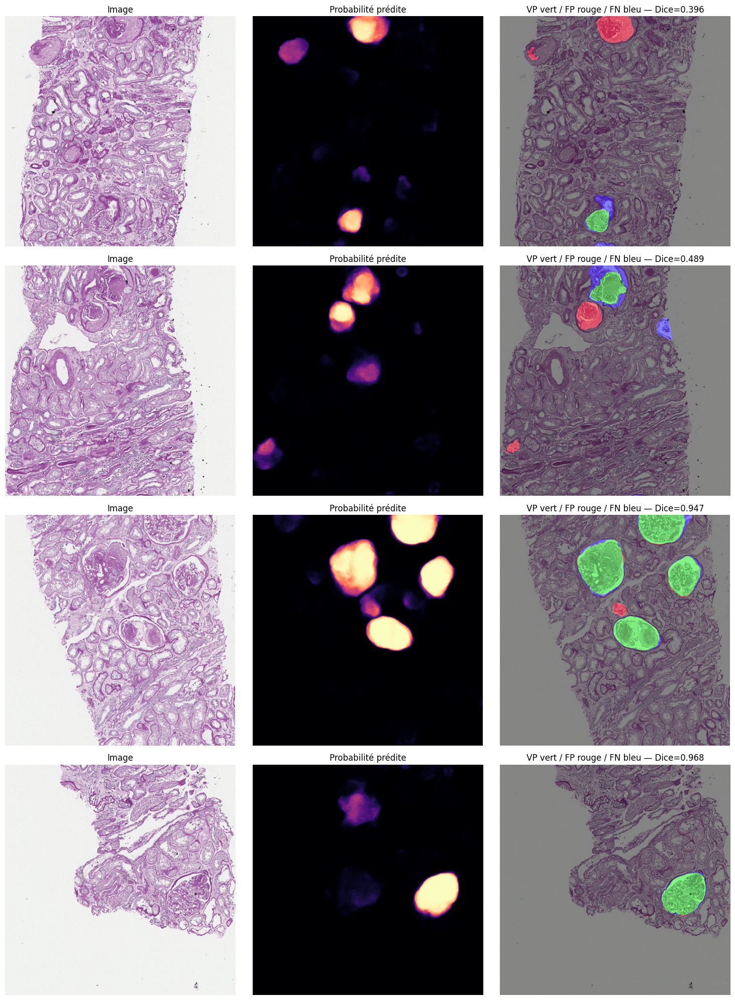

In [ ]:
def final_mask(prob, cfg):
    # Probabilités -> masque binaire final, selon les réglages retenus
    pred = prob > cfg["threshold"]
    return postprocess(pred, cfg["min_area"]) if cfg["postprocess"] else pred


best_probs = val_probs[BEST_MODE]
per_image = [dice(final_mask(p, INFERENCE), m) for p, m in zip(best_probs, val_dataset.masks)]

# --- Dice par image, de la pire à la meilleure ---
order = np.argsort(per_image)
for i in order:
    print(f"{per_image[i]:.4f}  {val_dataset.pairs[i][0].name[-50:]}")
print(f"\nDice moyen train_AKI : {np.mean(per_image):.4f} (min {np.min(per_image):.3f}, max {np.max(per_image):.3f})")

# --- Visualisation : les 2 pires et les 2 meilleures images ---
show = list(order[:2]) + list(order[-2:])
fig, axes = plt.subplots(len(show), 3, figsize=(15, 5 * len(show)))
for row, i in enumerate(show):
    image, gt = val_dataset.images[i], val_dataset.masks[i]
    pred = final_mask(best_probs[i], INFERENCE)
    overlay = np.zeros((*gt.shape, 3), dtype=np.float32)
    overlay[gt & pred] = (0, 1, 0)       # vert  : vrai positif
    overlay[~gt & pred] = (1, 0, 0)      # rouge : faux positif
    overlay[gt & ~pred] = (0, 0, 1)      # bleu  : faux négatif
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Image")
    axes[row, 1].imshow(best_probs[i], cmap="magma", vmin=0, vmax=1)
    axes[row, 1].set_title("Probabilité prédite")
    axes[row, 2].imshow(image)
    axes[row, 2].imshow(overlay, alpha=0.45)
    axes[row, 2].set_title(f"VP vert / FP rouge / FN bleu — Dice={per_image[i]:.3f}")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Soumission et utilisation du modèle sur de nouvelles images

### Ce que contient `unet_scratch_weights.pth`
- les poids du réseau (version EMA) ;
- l'architecture (`base_channels`, `depth`, `dropout`) et la résolution de travail (`scale`) ;
- les réglages d'inférence retenus en section 7 (`threshold`, `tta`, `zooms`, `postprocess`, `min_area`).

`load_model` recrée le réseau à partir de ce seul fichier. `predict_mask` applique toute la chaîne à une image RGB de **n'importe quelle taille**.

### Des pixels aux objets (instances)
Le sujet décrit chaque objet comme `O_k = (bounding box, masque)`. Les **composantes connexes** du masque binaire (`cv2.connectedComponentsWithStats`) donnent chaque glomérule, sa bounding box et son aire. Deux glomérules qui se touchent sont fusionnés, ce qui ne change rien au Dice.

### Fichier de soumission
`make_submission` prédit toutes les images d'un dossier (en ignorant les `*_mask*`) et écrit :
```
ID,mask
image_001,RLEstring1
```

### Mode d'emploi
- Jeu de test disponible : `TEST_DIR = Path("./dossier_test")`.
- Tant que `TEST_DIR = None`, la cellule refait la chaîne complète sur `train_AKI` (fichier de poids → CSV → décodage RLE). Le Dice recalculé doit être **identique** à celui de la section 7.
- Pour les organisateurs, le script autonome `predict_glomeruli.py` fait la même chose sans le notebook :
  `python predict_glomeruli.py --input dossier_images --weights unet_scratch_weights.pth --out submission.csv`

In [ ]:
def load_model(path=WEIGHTS_PATH):
    # Recrée le réseau à partir du fichier de poids seul (architecture + réglages d'inférence inclus)
    ckpt = torch.load(path, map_location=device)
    cfg = ckpt["config"]
    net = UNet(cfg["base_channels"], cfg["depth"], cfg["dropout"]).to(device)
    net.load_state_dict(ckpt["state_dict"])
    net.eval()
    return net, cfg


def predict_mask(net, cfg, image_rgb):
    # Chaîne complète pour une image : probabilités -> seuil -> post-traitement
    prob = predict_proba(net, image_rgb, tta=cfg["tta"], zooms=tuple(cfg["zooms"]), scale=cfg["scale"])
    return final_mask(prob, cfg)


def extract_instances(binary_mask):
    # Masque binaire -> liste d'objets O_k = {bbox (x, y, largeur, hauteur), aire, masque}
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    return [{"bbox": tuple(int(v) for v in stats[k, :4]), "area": int(stats[k, 4]), "mask": labels == k}
            for k in range(1, n)]                    # l'étiquette 0 est le fond


IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


def make_submission(net, cfg, folder, out_csv="submission.csv"):
    # Prédit toutes les images d'un dossier (sauf les masques) et écrit le CSV "ID,mask"
    paths = sorted(p for p in Path(folder).iterdir()
                   if p.suffix.lower() in IMAGE_EXTENSIONS and "_mask" not in p.stem)
    with open(out_csv, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["ID", "mask"])
        for p in tqdm(paths, desc="Prédiction"):
            writer.writerow([p.stem, rle_encode(predict_mask(net, cfg, read_rgb(p)))])
    print(f"{len(paths)} prédictions écrites dans {out_csv}")
    return out_csv


final_model, final_cfg = load_model(WEIGHTS_PATH)
print("Réglages chargés depuis le fichier :", final_cfg)

TEST_DIR = None   # <- mettre Path("./dossier_test") quand le jeu de test sera disponible

if TEST_DIR is not None:
    csv_path = make_submission(final_model, final_cfg, TEST_DIR, "submission.csv")
else:
    # Pas de test : on vérifie toute la chaîne (fichier de poids -> CSV -> RLE décodé) sur train_AKI
    csv_path = make_submission(final_model, final_cfg, VAL_DIR, "submission_val_check.csv")
    with open(csv_path) as f:
        rows = {row["ID"]: row["mask"] for row in csv.DictReader(f)}
    scores = []
    for img_path, mask_path in val_pairs:
        gt = read_mask(mask_path)
        scores.append(dice(rle_decode(rows[img_path.stem], gt.shape), gt))
    print(f"Dice moyen recalculé depuis le CSV : {np.mean(scores):.4f} (doit être égal à celui de la section 7)")

# --- Exemple : objets détectés sur la première image de validation ---
instances = extract_instances(predict_mask(final_model, final_cfg, val_dataset.images[0]))
print(f"{len(instances)} glomérules détectés :")
for k, inst in enumerate(instances, 1):
    print(f"  O_{k}: bbox (x, y, w, h) = {inst['bbox']}, aire = {inst['area']} px")

Réglages chargés depuis le fichier : {'base_channels': 16, 'depth': 5, 'dropout': 0.2, 'scale': 0.375, 'threshold': 0.45, 'postprocess': True, 'min_area': 1000, 'tta': True, 'zooms': (0.6, 0.8, 1.0)}


Prédiction:   0%|          | 0/11 [00:00<?, ?it/s]

11 prédictions écrites dans submission_val_check.csv


Dice moyen recalculé depuis le CSV : 0.7810 (doit être égal à celui de la section 7)


2 glomérules détectés :
  O_1: bbox (x, y, w, h) = (470, 214, 239, 222), aire = 37915 px
  O_2: bbox (x, y, w, h) = (740, 332, 133, 90), aire = 8178 px
